# Q3: Image Classification (CIFAR-10)

Compare four scikit-learn classifiers (Decision Tree, ANN, SVM, kNN) on CIFAR-10.

CIFAR-10 has 60,000 32x32 colour images across 10 classes (50,000 train / 10,000 test). Dataset info: https://www.cs.toronto.edu/~kriz/cifar.html

Note: SVM and kNN can be slow to train on the full 50,000-image training set with raw pixel features. Consider training on a subsample (e.g. 5,000-10,000 images) if runtime is an issue, and say so in your report.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from tensorflow.keras.datasets import cifar10   # only used to download the data

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]


In [3]:
def load_cifar10():
    # load CIFAR-10 train/test images and labels
    (X_train, y_train), (X_test, y_test) = cifar10.load_data()
    return X_train, y_train.ravel(), X_test, y_test.ravel()   # labels: (N,1) -> (N,)

# load the data
X_train, y_train, X_test, y_test = load_cifar10()
print(X_train.shape, X_test.shape)    # (50000, 32, 32, 3) (10000, 32, 32, 3)

# subsample the training set for runtime reasons
rng = np.random.default_rng(42)
idx = rng.permutation(len(X_train))[:10000]
X_train, y_train = X_train[idx], y_train[idx]
print("Training on", len(X_train), "images")


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1749s 10us/step
(50000, 32, 32, 3) (10000, 32, 32, 3)
Training on 10000 images


The dataset consists of 32 x 32 colour images from CIFAR-10 of 10 categories (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).

They must be classified using four scikit-learn classifiers: a Decision Tree, an Artificial Neural Network (ANN), a Support Vector Machine (SVM), and k-Nearest Neighbours (kNN). The same data, preprocessing, and evaluation protocol were used for all four so that the comparison is fair.

The standard split was used: 50,000 training images and 10,000 test images, with 1,000 test images per class.

Training subsample. Raw-pixel SVM and kNN scale poorly with training-set size. SVM training time grows roughly quadratically with the number of samples, and kNN must compare every test image against every stored training image. We therefore trained all four models on a random subsample of 10,000 of the 50,000 training images (a fixed random permutation with seed 42), which is the upper end of the range allowed in the assignment. Using the same subsample for every classifier keeps the comparison fair. The full 10,000-image test set was used for evaluation, so the reported accuracies are not affected by the subsampling of the test side. Because the subsample is random, the classes are only approximately balanced in it, although each class should have close to 1,000 images.

In [4]:
# Preprocess
def preprocess(X):
    X = X.reshape(len(X), -1)        # (N, 32, 32, 3) -> (N, 3072): one row per image
    return X.astype("float32") / 255.0   # pixel values from 0-255 to 0-1

# preprocess train & test features
X_train_p = preprocess(X_train)
X_test_p = preprocess(X_test)

# standardize: fit on TRAIN only, then apply the same transform to test
scaler = StandardScaler()
X_train_p = scaler.fit_transform(X_train_p)
X_test_p = scaler.transform(X_test_p)


Feature preparation.

Flattening. scikit-learn classifiers expect one feature vector per sample, so each image (3x32x3) was flattened into a vector of 3,072 raw pixel values. This discards all spatial structure, which turns out to matter for the results below.

Scaling. Pixel values were divided by 255 to lie in [0, 1], then standardised with StandardScaler (zero mean, unit variance per feature). The scaler was fitted on the training subsample only and then applied unchanged to the test set, so no test-set information influenced training.

In [5]:
# Define the four classifiers to compare
classifiers = {
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=42),
    "ANN": MLPClassifier(hidden_layer_sizes=(256,), max_iter=50,
                         early_stopping=True, random_state=42),
    "SVM": SVC(kernel="rbf", C=10, gamma="scale"),
    "kNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
}

Decision Tree: Limiting depth stops the tree from growing until it memorises the training data (an unrestricted tree on 3,072 features would fit the training set perfectly and generalise badly).


ANN (MLP): A single hidden layer is a simple baseline. Early stopping holds out 10% of the training data as a validation set (so the network effectively trains on about 9,000 images) and stops when validation score stops improving, which limits overfitting.

SVM: The RBF kernel allows non-linear decision boundaries. C=10 allows a moderately flexible margin, and gamma='scale' sets the kernel width from the data variance.

kNN: k=5 is a common default that smooths over some noise without blurring class boundaries too much.

----------------------------------
Learning <Decision Tree>
----------------------------------
Classifying test data......
Evaluating results.....
Accuracy: 0.2399
Precision: 0.23950087027602435
Recall: 0.2399
F-measure: 0.23924611499951398
Confusion Matrix:


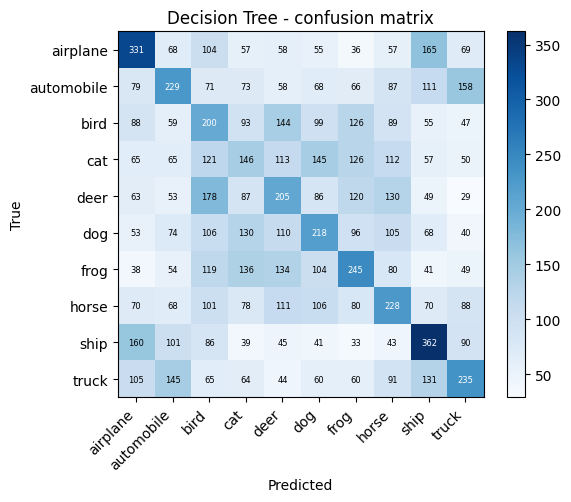

----------------------------------
Learning <ANN>
----------------------------------
Classifying test data......
Evaluating results.....
Accuracy: 0.4413
Precision: 0.440288017811637
Recall: 0.4413
F-measure: 0.43933475854246434
Confusion Matrix:


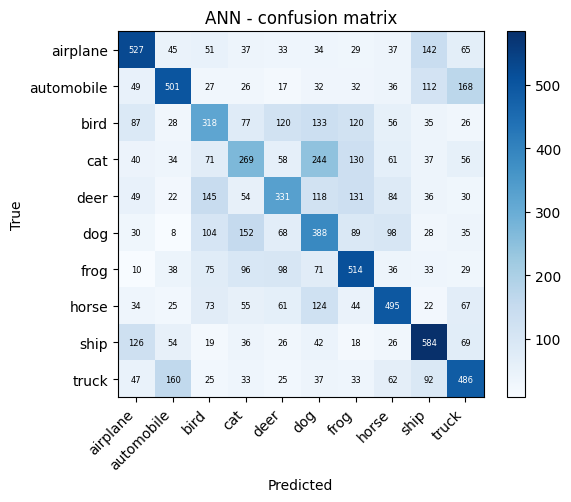

----------------------------------
Learning <SVM>
----------------------------------
Classifying test data......
Evaluating results.....
Accuracy: 0.4849
Precision: 0.4864905399584744
Recall: 0.4849
F-measure: 0.48492036553970264
Confusion Matrix:


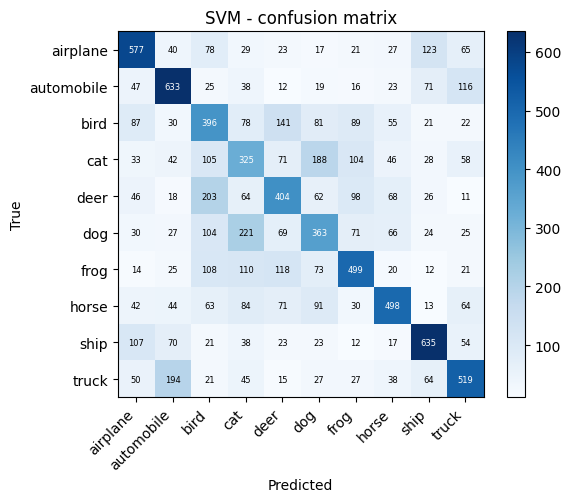

----------------------------------
Learning <kNN>
----------------------------------
Classifying test data......
Evaluating results.....
Accuracy: 0.2905
Precision: 0.39190966189481674
Recall: 0.29050000000000004
F-measure: 0.2728529559199175
Confusion Matrix:


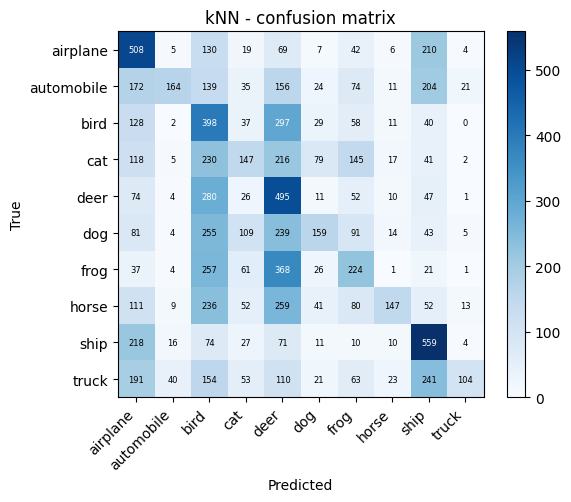

In [6]:
# Train + evaluate each classifier
results = {}

for name, clf in classifiers.items():
    print("----------------------------------")
    print(f"Learning <{name}>")
    print("----------------------------------")
    # fit clf on training data
    clf.fit(X_train_p, y_train)


    print("Classifying test data......")
    # predict on test data
    y_pred = clf.predict(X_test_p)


    # compute evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f_measure = f1_score(y_test, y_pred, average="macro", zero_division=0)

    print("Evaluating results.....")
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F-measure:", f_measure)
    print("Confusion Matrix:")

    # TODO: print/plot confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(10), CLASS_NAMES, rotation=45, ha="right")
    plt.yticks(range(10), CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"{name} - confusion matrix")
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.show()


    results[name] = {"accuracy": accuracy, "precision": precision, "recall": recall, "f_measure": f_measure}


,accuracy,precision,recall,f_measure
Decision Tree,0.2399,0.2395,0.2399,0.2392
ANN,0.4413,0.4403,0.4413,0.4393
SVM,0.4849,0.4865,0.4849,0.4849
kNN,0.2905,0.3919,0.2905,0.2729


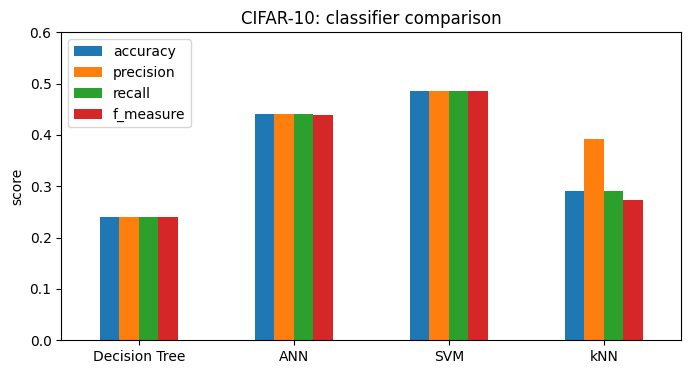

In [7]:
# Summary table comparing all four classifiers
summary = pd.DataFrame(results).T.round(4)
display(summary)

summary.plot(kind="bar", figsize=(8, 4))
plt.title("CIFAR-10: classifier comparison")
plt.ylabel("score")
plt.xticks(rotation=0)
plt.ylim(0, 0.6)
plt.legend(loc="upper left")
plt.show()

Analysis:

All four models receive the same input: a flat list of 3,072 numbers. A pixel at position (10, 10) can belong to a sky in one image and to a cat's fur in another, because objects move, rotate, change size and appear against different backgrounds. No single pixel, or simple function of a few pixels, reliably identifies an object. This explains why even the best model stays below 50%. The models differ in how well they can combine pixels, and that is what separates them.

SVM (48.5%): best overall

The RBF kernel lets the SVM build smooth, non-linear boundaries that depend on all 3,072 features at once. SVMs also work well in high-dimensional spaces because the margin-based objective helps against overfitting even when features are numerous. It was the best or near-best model in almost every class, with the clearest advantages on automobile (63.3%), ship (63.5%) and airplane (57.7%). It also had the highest and most balanced precision and recall (0.4865 and 0.4849), meaning it did not strongly favour any particular class.

ANN (44.1%): second best

The hidden layer learns weighted combinations of pixels, so it can detect simple colour and brightness patterns that a tree cannot. It came within about 4 points of the SVM and was actually better on dog (38.8% vs 36.3%) and frog (51.4% vs 49.9%). It is a little behind the SVM overall, probably for these reasons: only about 9,000 images were used for fitting because 10% went to the early-stopping validation set; a single hidden layer cannot build up hierarchical features; and an MLP on flat pixels has no built-in notion of spatial locality. A larger or deeper network, more data, or longer training might narrow the gap, but we did not test this.

6.4 kNN (29.1%): unbalanced predictions

kNN classifies by Euclidean distance in 3,072-dimensional pixel space. Two images are “close” when their overall colours and brightness are similar, not when they show the same object. In very high dimensions, distances also become less discriminative. The confusion matrix shows a distinctive failure pattern. By summing the columns, kNN predicted the class “deer” about 2,280 times, “bird” about 2,150 times, “airplane” about 1,640 times and “ship” about 1,460 times, while predicting “truck” only about 155 times, “automobile” about 250 times and “horse” about 250 times (out of 10,000 predictions; a balanced predictor would give about 1,000 each). Images with plain, uniform backgrounds (blue sky or water, green or brown foliage) lie close to many other images, so they act as common nearest neighbours and attract many predictions. Objects such as cars and trucks, which appear in many colours against cluttered street backgrounds, rarely end up as nearest neighbours of one another. This is a known effect of distance-based methods in high dimensions. It also explains the per-class accuracies: kNN does well on deer (49.5%), ship (55.9%) and airplane (50.8%) but poorly on truck (10.4%), horse (14.7%) and cat (14.7%).

This also explains why kNN's macro precision (0.39) is much higher than its recall (0.29). The rarely predicted classes (automobile, truck, horse) are right most of the time when predicted (roughly 59–67% of the time), which lifts the macro-average of precision. The heavily over-predicted classes (bird, deer) have low precision (about 18% and 22%), but those low values are only two of the ten classes in the average, while recall is limited for every class that kNN under-predicts. For kNN, accuracy is therefore a more reliable single summary than precision.

6.5 Decision Tree (24.0%): weakest

A decision tree makes a sequence of threshold tests on single pixels. A single pixel carries almost no information about object identity, so the splits are weak, and many tests across the 3,072 features are needed to separate the classes. It was the lowest-scoring model, and its confusion matrix is the least concentrated on the diagonal (for example, cat 14.6% and bird 20.0%). Its best classes, ship (36.2%) and airplane (33.1%), are the ones where a global colour cue (blue background) helps. Limiting max_depth to 20 reduces memorisation but cannot fix the fundamental mismatch between axis-aligned pixel splits and image data.

Patterns in the confusion matrices (shared across models)

Several confusions appear in every matrix, which suggests they come from the data and not from any one algorithm:

Cat and dog: For the SVM, 188 cats were labelled as dogs and 221 dogs as cats. For the ANN, 244 cats were predicted as dogs. These animals have similar body shapes, fur textures and colours, and they appear in similar indoor and outdoor settings. Cat is the weakest or near-weakest class for the tree, ANN and SVM.
Automobile and truck. In the SVM matrix, 194 trucks were predicted as automobiles and 116 automobiles as trucks (168 and 160 in the ANN). Both are vehicles with wheels, similar colours and similar road backgrounds.
Airplane and ship. The SVM mislabelled 123 airplanes as ships and 107 ships as airplanes. In both categories, large areas of the image are plain blue or grey (sky or sea), which pixel-level methods mostly see as the same pattern.
Bird, deer and horse (animals on natural backgrounds). For example, 203 deer were predicted as birds by the SVM. These classes share green and brown backgrounds, and without shape information they are hard to separate.

In short, the models rely mainly on colour and background, not on object shape, so categories that share backgrounds or colour palettes are confused with each other, and categories with a distinctive background (ship, airplane, and for some models automobile) are classified best.